# HPD 4 — Servidor MCP y conexión segura a datos locales

<figure>
<a
href="https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/bloque2/hpd4-servidor-mcp.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

> **Competencias:** [CE-3](../index.qmd#sec-competencias-especificas)

> **Objetivos**
>
> - Implementar un servidor MCP con FastMCP que exponga datos de
>   facturación
> - Definir herramientas (tools) y recursos (resources) tipados con
>   Python
> - Conectar un cliente LLM y dejar que decida qué tool usar
> - Aplicar y probar medidas de seguridad (solo lectura, sanitización,
>   límites)
> - Analizar riesgos: prompt injection, data leakage
>
> ## Materiales
>
> - Librerías: `fastmcp`, `sqlite3` (stdlib), `openai`, `python-dotenv`
> - Base de datos SQLite de ejemplo: **Chinook** (tienda de música
>   digital, se descarga en el notebook)
> - LLM: API Llamus US (`https://llamus.cs.us.es/api/v1`) o local
>   (Ollama)
>
> ## Pipeline
>
> 1.  **Setup:** descargar la base Chinook y abrirla en modo solo
>     lectura
> 2.  **Servidor:** implementar tools y resources con FastMCP
> 3.  **Cliente:** conectar un LLM y probar consultas en lenguaje
>     natural
> 4.  **Seguridad:** sanitización, límites, test de ataques
> 5.  **Evaluación:** batería de preguntas y análisis de riesgos

> **¿Por qué necesitas esto?**
>
> Imagina que trabajas como analista en una empresa con 3 sistemas
> distintos: un ERP con la facturación, un CRM con clientes y hojas de
> cálculo con inventario. Conectar un asistente conversacional a cada
> uno requeriría 3 integraciones distintas, cada una con su propia
> autenticación y formato. MCP (Model Context Protocol) resuelve esto:
> es un estándar abierto que actúa como un *USB-C para LLM*. Defines un
> servidor por cada fuente de datos y cualquier cliente LLM se conecta
> igual.
>
> En este taller construyes tu primer servidor MCP sobre una base de
> datos real de ejemplo (Chinook, con facturas, clientes, catálogo y
> empleados). La arquitectura escala a cualquier fuente de datos: SQL,
> APIs REST, archivos locales, servicios cloud. El protocolo es el
> mismo.

# Parte 1 — Setup y base de datos

Empezamos instalando dependencias y descargando la base de datos
Chinook.

> **Antes de empezar**
>
> Ejecuta **ya** la celda de instalación de más abajo y sigue leyendo
> mientras termina: tarda unos 2 minutos. Si al acabar aparece un aviso
> en rojo sobre *dependency conflicts* (`google-colab`, `requests`,
> `opentelemetry`), ignóralo: son paquetes que trae Colab y no afectan a
> este taller.

In [1]:
!pip install -q fastmcp==3.3.1 openai==2.38.0 python-dotenv==1.2.2

In [2]:
import os, sqlite3, tempfile, json, re, time, urllib.request
from pathlib import Path
"""
Setup compartido para la API key de Llamus en todos los notebooks.
Inyectado en cada .qmd/.ipynb vía scripts/sync_setup_keys.py (pre-render).

Orden de resolución:
  1. .env local (python-dotenv)
  2. os.environ ya configurado externamente
  3. Google Colab userdata: secret "LLAMUS_API_KEY" (preferente) o "LLM_API_KEY"

Las celdas posteriores pueden leer la clave con os.environ.get("LLM_API_KEY").
"""

import os


def _load_llm_api_key():
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass

    if not os.getenv("LLM_API_KEY"):
        try:
            from google.colab import userdata
            for name in ("LLAMUS_API_KEY", "LLM_API_KEY"):
                try:
                    value = userdata.get(name)
                    if value:
                        os.environ["LLM_API_KEY"] = value
                        break
                except Exception:
                    continue
        except ImportError:
            pass


_load_llm_api_key()

if os.getenv("LLM_API_KEY"):
    print("✓ LLM_API_KEY cargada.")
else:
    print("⚠️  LLM_API_KEY no encontrada.")
    print("    • Local: crea un archivo .env con LLM_API_KEY=tu_clave")
    print("    • Colab: añade un Secret 🔑 con nombre 'LLAMUS_API_KEY'")

os.environ["TOKENIZERS_PARALLELISM"] = "false"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
np.random.seed(42)

print("Librerías cargadas correctamente.")

✓ LLM_API_KEY cargada.
Librerías cargadas correctamente.

## 1.1 Descargar y abrir la base Chinook

[Chinook](https://github.com/lerocha/chinook-database) es una base de
datos de ejemplo de una tienda de música digital: catálogo (artistas,
álbumes, pistas, géneros), clientes, empleados y facturas. Fue creada
por Luis Rocha y se distribuye con **licencia MIT**. Los datos de
catálogo proceden de una biblioteca de iTunes real; clientes y empleados
son ficticios.

El fichero SQLite pesa unos 1 MB. Lo descargamos una vez, lo guardamos
en caché en el directorio temporal y lo abrimos en **modo solo lectura**
(`mode=ro`): el servidor MCP nunca debe poder modificar los datos.

In [3]:
CHINOOK_URL = "https://github.com/lerocha/chinook-database/raw/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"
CHINOOK_PATH = os.path.join(tempfile.gettempdir(), "chinook_cache", "Chinook_Sqlite.sqlite")

def _es_chinook(path) -> bool:
    """Comprueba que el fichero es SQLite y contiene la tabla Invoice."""
    try:
        con = sqlite3.connect(f"{Path(path).resolve().as_uri()}?mode=ro", uri=True)
        try:
            return con.execute(
                "SELECT 1 FROM sqlite_master WHERE type='table' AND name='Invoice'"
            ).fetchone() is not None
        finally:
            con.close()
    except sqlite3.DatabaseError:
        return False

def descargar_chinook(url=CHINOOK_URL, destino=CHINOOK_PATH, timeout=60) -> str:
    """Descarga Chinook (~1 MB) al directorio temporal. Si ya existe la copia en caché, no la descarga de nuevo."""
    if os.path.exists(destino) and _es_chinook(destino):
        return destino
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    tmp = destino + ".part"
    try:
        with urllib.request.urlopen(url, timeout=timeout) as resp:
            data = resp.read()
        with open(tmp, "wb") as f:
            f.write(data)
    except Exception as e:
        raise RuntimeError(
            f"No se pudo descargar la base Chinook desde:\n  {url}\n"
            f"Causa: {e}\n"
            "Comprueba la conexión a Internet. Si el problema persiste, descarga el fichero "
            f"manualmente y guárdalo en:\n  {destino}"
        ) from e
    if not _es_chinook(tmp):
        os.remove(tmp)
        raise RuntimeError("El fichero descargado no es la base Chinook (SQLite con tabla Invoice).")
    os.replace(tmp, destino)
    return destino

def conectar_solo_lectura(path: str):
    """Abre la base en modo solo lectura (mode=ro) y con un autorizador que solo permite leer:
    el motor rechaza ATTACH, PRAGMA, escrituras y cualquier otra acción aunque el validador falle."""
    uri = Path(path).resolve().as_uri() + "?mode=ro"
    con = sqlite3.connect(uri, uri=True, check_same_thread=False)
    permitidas = {sqlite3.SQLITE_SELECT, sqlite3.SQLITE_READ, sqlite3.SQLITE_FUNCTION}
    con.set_authorizer(lambda accion, *_: sqlite3.SQLITE_OK if accion in permitidas else sqlite3.SQLITE_DENY)
    return con

DB_PATH = descargar_chinook()
db = conectar_solo_lectura(DB_PATH)
print(f"✅ Chinook abierta en modo solo lectura: {DB_PATH}")

✅ Chinook abierta en modo solo lectura: /var/folders/5q/dq_s1n552d37rqhcc02ppsn00000gn/T/chinook_cache/Chinook_Sqlite.sqlite

In [4]:
# Explorar el esquema y unas muestras de datos
print("=" * 60)
print("TABLAS PRINCIPALES — Chinook")
print("=" * 60)

for tabla in ["Customer", "Invoice", "InvoiceLine", "Track", "Album", "Artist", "Genre"]:
    columnas = [d[0] for d in db.execute(f"SELECT * FROM {tabla} LIMIT 0").description]
    print(f"  {tabla}({', '.join(columnas)})")

print("\n--- Muestra: 3 clientes ---")
for row in db.execute("SELECT CustomerId, FirstName, LastName, Country FROM Customer LIMIT 3"):
    print(f"  {row}")

print("\n--- Top 5 países por facturación ---")
for row in db.execute("""
    SELECT BillingCountry, ROUND(SUM(Total), 2) AS total
    FROM Invoice GROUP BY BillingCountry ORDER BY total DESC LIMIT 5
"""):
    print(f"  {row[0]}: {row[1]:.2f}")

TABLAS PRINCIPALES — Chinook
  Customer(CustomerId, FirstName, LastName, Company, Address, City, State, Country, PostalCode, Phone, Fax, Email, SupportRepId)
  Invoice(InvoiceId, CustomerId, InvoiceDate, BillingAddress, BillingCity, BillingState, BillingCountry, BillingPostalCode, Total)
  InvoiceLine(InvoiceLineId, InvoiceId, TrackId, UnitPrice, Quantity)
  Track(TrackId, Name, AlbumId, MediaTypeId, GenreId, Composer, Milliseconds, Bytes, UnitPrice)
  Album(AlbumId, Title, ArtistId)
  Artist(ArtistId, Name)
  Genre(GenreId, Name)

--- Muestra: 3 clientes ---
  (1, 'Luís', 'Gonçalves', 'Brazil')
  (2, 'Leonie', 'Köhler', 'Germany')
  (3, 'François', 'Tremblay', 'Canada')

--- Top 5 países por facturación ---
  USA: 523.06
  Canada: 303.96
  France: 195.10
  Brazil: 190.10
  Germany: 156.48

------------------------------------------------------------------------

# Parte 2 — Primer servidor MCP

Creamos un servidor con FastMCP que expone una herramienta de consulta
SQL. De momento sin sanitización — la añadiremos en la Parte 5 cuando
hablemos de seguridad.

## 2.1 Servidor mínimo con una tool

In [5]:
from fastmcp import FastMCP

mcp = FastMCP("Servidor Facturación Chinook")

# ─── COMPLETAR: implementa la tool consultar_sql ───
@mcp.tool()
def consultar_sql(query: str) -> str:
    """
    Ejecuta una consulta SQL sobre la base de datos de facturación (Chinook).

    Schema disponible (principales):
      - Customer(CustomerId, FirstName, LastName, Company, City, Country, Email, ...)
      - Invoice(InvoiceId, CustomerId, InvoiceDate, BillingCountry, BillingCity, Total)
      - InvoiceLine(InvoiceLineId, InvoiceId, TrackId, UnitPrice, Quantity)
      - Track(TrackId, Name, AlbumId, GenreId, Composer, Milliseconds, UnitPrice)
      - Album(AlbumId, Title, ArtistId)  ·  Artist(ArtistId, Name)  ·  Genre(GenreId, Name)

    Args:
        query: consulta SQL (solo SELECT). Ejemplo:
               "SELECT FirstName, LastName FROM Customer WHERE Country = 'Brazil'"

    Returns:
        Resultados de la consulta en formato tabla.
    """
    # TODO: usar db.execute(query) y formatear resultado
    #   columnas = [d[0] for d in cursor.description]
    #   filas = cursor.fetchmany(20)
    # TODO: envolver en try/except y devolver string siempre
    # NOTA: db es la variable global de la conexión (Parte 1, solo lectura)

    pass  # ← completar

print("✅ Servidor MCP creado con 1 tool: consultar_sql")

✅ Servidor MCP creado con 1 tool: consultar_sql

In [6]:
# Probar la tool directamente (sin lanzar el servidor)
print("=== Probando tool consultar_sql directamente ===")
print("1. Clientes de Brasil:")
# print(consultar_sql("SELECT FirstName, LastName FROM Customer WHERE Country = 'Brazil'"))

print("\n2. Álbumes de AC/DC:")
# print(consultar_sql("SELECT Title FROM Album JOIN Artist USING (ArtistId) WHERE Artist.Name = 'AC/DC'"))

print("\n⚠️  Descomenta las líneas cuando hayas implementado la tool.")

=== Probando tool consultar_sql directamente ===
1. Clientes de Brasil:

2. Álbumes de AC/DC:

⚠️  Descomenta las líneas cuando hayas implementado la tool.

> **FastMCP frente al SDK oficial**
>
> FastMCP es una capa simplificada sobre el SDK `mcp`. Ventajas: - El
> docstring de la función se convierte automáticamente en la descripción
> de la tool para el LLM - Los type hints de Python (`str`, `int`,
> `float`) generan el JSON Schema - No necesitas escribir
> `@server.list_tools()` ni `@server.call_tool()` manualmente

------------------------------------------------------------------------

# Parte 3 — Resources y más herramientas

Un servidor MCP de verdad expone más que una sola tool. Añadimos
resources (datos de solo lectura) y tools especializadas para consultas
frecuentes.

## 3.1 Resource: schema de la base de datos

In [7]:
# ─── COMPLETAR: implementa el resource schema://tablas ───
@mcp.resource("schema://tablas")
def esquema_bd() -> str:
    """
    Devuelve el DDL completo de todas las tablas de la base de datos.
    El LLM puede consultar este recurso para saber qué columnas existen
    antes de escribir una query SQL.
    """
    # TODO: usar db.execute() para obtener el DDL de cada tabla
    #   cursor = db.execute('SELECT sql FROM sqlite_master WHERE type="table"')
    # NOTA: db es la variable global de la conexión (solo lectura)

    pass  # ← completar

In [8]:
# Probar el resource directamente
print("=== Probando resource schema://tablas ===")
# print(esquema_bd())
print("⚠️  Descomenta la línea anterior cuando hayas implementado el resource.")

=== Probando resource schema://tablas ===
⚠️  Descomenta la línea anterior cuando hayas implementado el resource.

## 3.2 Tool: buscar cliente por ID

In [9]:
# ─── COMPLETAR: implementa la tool cliente_por_id ───
@mcp.tool()
def cliente_por_id(id_cliente: int) -> str:
    """
    Busca un cliente por su ID y devuelve su ficha básica y un resumen de compras.
    Por privacidad no se devuelven el email, el teléfono ni la dirección.

    Args:
        id_cliente: ID del cliente (número entero).

    Returns:
        Datos del cliente o mensaje de error si no existe.

    Ejemplo: cliente_por_id(1) → 'Luís Gonçalves | Brazil | São José dos Campos | 7 facturas | 39.62 total'
    """
    # TODO: usar db.execute() con parámetro ? para buscar por CustomerId
    #   Combina Customer con Invoice (LEFT JOIN) para contar facturas y sumar Total
    # NOTA: db es la variable global de la conexión (solo lectura)

    pass  # ← completar

In [10]:
print("=== Probando tool cliente_por_id ===")
# print(cliente_por_id(1))
# print(cliente_por_id(9999))  # Debería dar error
print("⚠️  Descomenta las líneas cuando hayas implementado la tool.")

=== Probando tool cliente_por_id ===
⚠️  Descomenta las líneas cuando hayas implementado la tool.

## 3.3 Tool: resumen de un álbum

In [11]:
# ─── COMPLETAR: implementa la tool resumen_album ───
@mcp.tool()
def resumen_album(id_album: int) -> str:
    """
    Devuelve un resumen del álbum: título, artista, número de pistas,
    unidades vendidas e ingresos generados.

    Args:
        id_album: ID del álbum (número entero).

    Returns:
        Resumen en formato texto.

    Ejemplo: resumen_album(1) → 'For Those About To Rock We Salute You | AC/DC | 10 pistas | 10 unidades vendidas | 9.90 ingresos'
    """
    # TODO: usar db.execute() con JOIN entre Album, Artist, Track e InvoiceLine
    #   unidades = SUM(InvoiceLine.Quantity); ingresos = SUM(UnitPrice * Quantity)
    # NOTA: db es la variable global de la conexión (solo lectura)

    pass  # ← completar

In [12]:
print("=== Probando tool resumen_album ===")
# print(resumen_album(1))
# print(resumen_album(2))
print("⚠️  Descomenta las líneas cuando hayas implementado la tool.")

=== Probando tool resumen_album ===
⚠️  Descomenta las líneas cuando hayas implementado la tool.

## 3.4 Resource: estadísticas de la base de datos

In [13]:
# ─── COMPLETAR: implementa el resource stats://resumen ───
@mcp.resource("stats://resumen")
def stats_servidor() -> str:
    """
    Devuelve un resumen agregado de la base de datos:
    número de clientes, facturas, facturación total, pistas y álbumes.
    """
    # TODO: usar db.execute() con COUNT(*) y SUM(Total) sobre las tablas correspondientes
    # NOTA: db es la variable global de la conexión (solo lectura)

    pass  # ← completar

In [14]:
print("=== Probando resource stats://resumen ===")
# print(stats_servidor())
print("⚠️  Descomenta la línea anterior cuando hayas implementado el resource.")

=== Probando resource stats://resumen ===
⚠️  Descomenta la línea anterior cuando hayas implementado el resource.

In [15]:
# Verificar cuántas tools y resources tenemos registrados
tools = await mcp.list_tools()
resources = await mcp.list_resources()
print(f"✅ Servidor MCP: {len(tools)} tools, {len(resources)} resources registrados")

✅ Servidor MCP: 3 tools, 2 resources registrados

------------------------------------------------------------------------

# Parte 4 — Conexión desde un cliente LLM

Ahora conectamos un LLM real al servidor MCP. El LLM recibirá la lista
de tools disponibles (con sus descripciones y schemas) y decidirá cuál
usar para cada pregunta.

## 4.1 Configurar el LLM

In [16]:
from openai import OpenAI

LLM_KEY = os.getenv("LLM_API_KEY")
LLM_URL = os.getenv("LLM_URL", "https://llamus.cs.us.es/api/v1")
LLM_MODEL = os.getenv("LLM_MODEL", "gemma4:26b")

if not LLM_KEY:
    print("⚠️  Crea un archivo .env con:\n    LLM_API_KEY=tu_api_key")
else:
    client = OpenAI(base_url=LLM_URL, api_key=LLM_KEY)
    print("✅ Cliente OpenAI configurado.")

✅ Cliente OpenAI configurado.

## 4.2 Función de consulta al servidor MCP

Como el servidor MCP se comunica por stdio (no por HTTP), no podemos
llamarlo directamente desde el notebook sin lanzarlo como subproceso.
Para simplificar la sesión presencial, vamos a simular la conexión
cliente-servidor invocando las tools de FastMCP directamente
(equivalente funcional).

> **¿Por qué simulamos la conexión?**
>
> En producción, el cliente LLM lanza el servidor MCP como subproceso y
> se comunica por stdin/stdout. Pero en un notebook de Colab, lanzar
> subprocesos es complejo. Llamar a las tools directamente produce
> exactamente el mismo resultado y nos permite centrarnos en lo
> importante: ver cómo el LLM decide qué tool usar.

> **De LangChain (HPD 2) a la API de OpenAI**
>
> En HPD 2 usaste `create_agent` de LangChain para crear el agente. Aquí
> implementas el mismo bucle ReAct manualmente con la API de OpenAI. La
> diferencia es que las tools no son funciones Python decoradas con
> `@tool` — están en un servidor MCP independiente. El patrón de
> razonamiento (LLM decide → ejecuta tool → observa resultado →
> responde) es exactamente el mismo.

In [17]:
def ejecutar_tool_mcp(nombre: str, args: dict) -> str:
    """
    Invoca una tool MCP por nombre. Simula lo que haría un cliente MCP real.
    """
    tools_disponibles = {
        "consultar_sql": consultar_sql,
        "cliente_por_id": cliente_por_id,
        "resumen_album": resumen_album,
    }

    if nombre not in tools_disponibles:
        return f"Error: tool '{nombre}' no encontrada. Disponibles: {list(tools_disponibles.keys())}"

    try:
        return tools_disponibles[nombre](**args)
    except Exception as e:
        return f"Error ejecutando {nombre}: {e}"

# ─── COMPLETAR: define las tools en formato OpenAI function calling ───
tools_definition = [
    {
        "type": "function",
        "function": {
            "name": "consultar_sql",
            "description": "Ejecuta una consulta SQL SELECT sobre la base de facturación Chinook. Tablas: Customer, Invoice, InvoiceLine, Track, Album, Artist, Genre.",
            "parameters": {
                "type": "object",
                "properties": {
                    "query": {"type": "string", "description": "Consulta SQL SELECT"}
                },
                "required": ["query"]
            }
        }
    },
    # TODO: Añadir definición de cliente_por_id
    # {"type": "function", "function": {"name": "cliente_por_id", ...}},
    # TODO: Añadir definición de resumen_album
    # {"type": "function", "function": {"name": "resumen_album", ...}},
]

print(f"Tools definidas: {[t['function']['name'] for t in tools_definition]}")

Tools definidas: ['consultar_sql']

In [18]:
def preguntar_al_llm(pregunta: str) -> str:
    """
    Envía una pregunta al LLM. Si el LLM decide usar una tool,
    la ejecutamos y devolvemos el resultado al LLM para que genere la respuesta final.

    Este es el patrón base de Tool Calling (el mismo que usaste en HPD 2,
    pero aquí las tools están en un servidor MCP en lugar de LangChain).
    """
    if not LLM_KEY:
        return "⚠️  Configura LLM_API_KEY en .env"

    messages = [
        {"role": "system", "content": "Eres un analista de una tienda de música digital. Tienes acceso a una base de datos de facturación (clientes, facturas, catálogo). Usa las herramientas disponibles para responder preguntas. Responde en español, de forma concisa."},
        {"role": "user", "content": pregunta}
    ]

    # ─── COMPLETAR: implementa el bucle de tool calling ───
    # TODO: Llamar a client.chat.completions.create con:
    #   model=LLM_MODEL, messages=messages, tools=tools_definition, tool_choice="auto"
    # TODO: Si la respuesta tiene tool_calls, ejecutar cada tool con ejecutar_tool_mcp()
    # TODO: Añadir el resultado al historial y volver a llamar al LLM
    # TODO: Devolver la respuesta final del LLM (response.choices[0].message.content)

    pass  # ← completar

print("✅ Función preguntar_al_llm definida.")

✅ Función preguntar_al_llm definida.

> **Esta es la celda más compleja del taller**
>
> Implementar el bucle de tool calling a mano requiere gestionar
> `tool_calls`, ejecutar las tools y reinyectar los resultados en el
> historial. El patrón es idéntico al que usaste en HPD 2 con LangChain,
> pero sin la abstracción. Si te atascas, repasa el bucle de tool
> calling de HPD 2 y la documentación de la API de OpenAI.

In [19]:
if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env para ver al LLM en acción.")
else:
    print("=== Probando cliente LLM + MCP ===\n")

    pregunta = "¿Cuántos clientes tenemos en Brasil?"
    print(f"PREGUNTA: {pregunta}")
    # respuesta = preguntar_al_llm(pregunta)
    # print(f"   RESPUESTA: {respuesta}")
    print("   ⚠️  Descomenta cuando hayas implementado preguntar_al_llm().")

=== Probando cliente LLM + MCP ===

PREGUNTA: ¿Cuántos clientes tenemos en Brasil?
   ⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

------------------------------------------------------------------------

# Parte 5 — Seguridad en MCP

Cada tool MCP es una superficie de ataque. El LLM recibe la entrada del
usuario y un atacante puede manipular el prompt para inyectar comandos
maliciosos. Vamos a proteger nuestro servidor.

<figure id="fig-hpd4-prompt-injection">
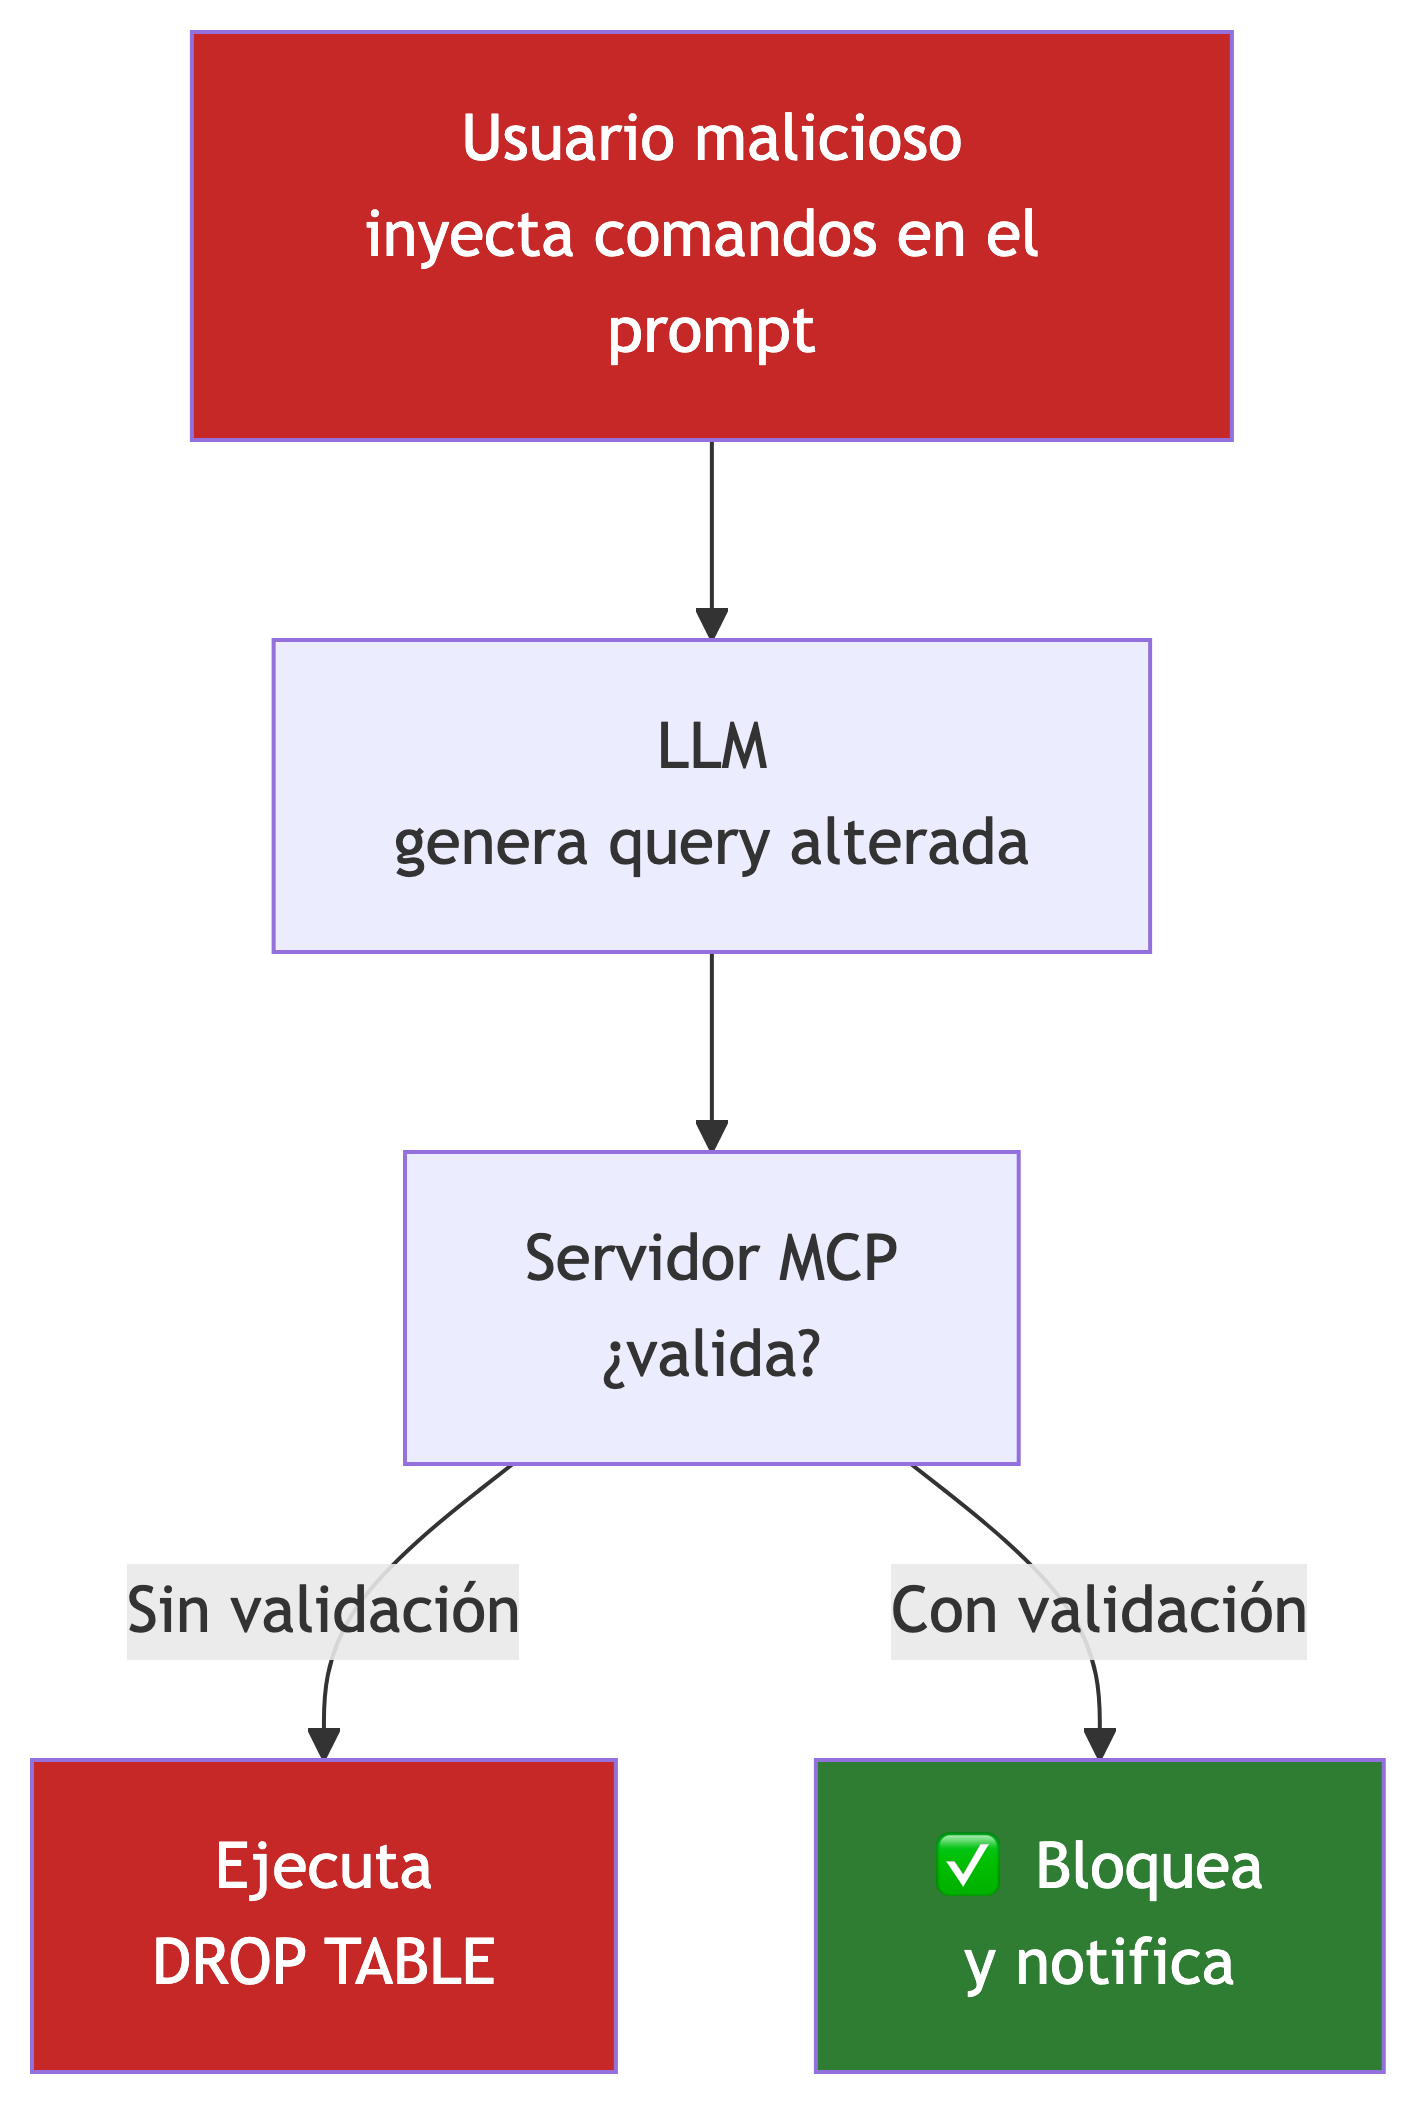
<figcaption>Figure 1</figcaption>
</figure>

## 5.1 Añadir sanitización

In [20]:
# ─── COMPLETAR: implementa la sanitización de queries SQL ───
PALABRAS_PROHIBIDAS = ["DROP", "DELETE", "UPDATE", "INSERT", "ALTER", "CREATE", "TRUNCATE"]

def sanitizar_query(query: str) -> str:
    """
    Valida y limpia una consulta SQL. Solo permite SELECT.

    Args:
        query: consulta SQL del usuario.

    Returns:
        La query original si es segura.

    Raises:
        ValueError si la query contiene comandos peligrosos.
    """
    # TODO: Convertir query a mayúsculas para comparar
    # TODO: Recorrer PALABRAS_PROHIBIDAS y lanzar ValueError si aparece alguna
    # TODO: Verificar que la query empieza por SELECT
    return query  # ← completar

# ─── COMPLETAR: actualiza consultar_sql para usar sanitizar_query ───
# Añade al principio de consultar_sql:
#   query = sanitizar_query(query)
# Si sanitizar_query lanza ValueError, captúralo y devuelve el mensaje de error

print("✅ Función sanitizar_query definida.")

✅ Función sanitizar_query definida.

> **Defensa en profundidad**
>
> La sanitización es la primera barrera, pero no la única. La conexión
> `db` ya está en modo solo lectura y con un autorizador que solo
> permite leer: aunque una consulta sorteara el filtro de palabras,
> SQLite la rechazaría. Compruébalo en la siguiente sección.

## 5.2 Probar ataques de prompt injection

Ejecutamos varios intentos de ataque para verificar que nuestras
defensas funcionan.

In [21]:
print("=" * 60)
print("TEST DE SEGURIDAD — Prompt Injection")
print("=" * 60)

ataques = [
    "DROP TABLE Customer",
    "DELETE FROM Invoice WHERE InvoiceId = 1",
    "INSERT INTO Genre VALUES (99, 'Hacker')",
    "UPDATE Invoice SET Total = 0",
    "SELECT * FROM Customer; DROP TABLE Invoice; --",
]

# ─── COMPLETAR: prueba cada ataque contra sanitizar_query ───
for ataque in ataques:
    # TODO: Llamar a sanitizar_query(ataque) dentro de try/except
    # TODO: Si lanza ValueError → ✅ Bloqueado
    # TODO: Si no lanza → ❌ Peligro
    print(f"  ? {ataque}")
    pass  # ← completar

print("\n⚠️  Completa el bucle para ver los resultados de cada ataque.")

TEST DE SEGURIDAD — Prompt Injection
  ? DROP TABLE Customer
  ? DELETE FROM Invoice WHERE InvoiceId = 1
  ? INSERT INTO Genre VALUES (99, 'Hacker')
  ? UPDATE Invoice SET Total = 0
  ? SELECT * FROM Customer; DROP TABLE Invoice; --

⚠️  Completa el bucle para ver los resultados de cada ataque.

## 5.3 Límite de resultados

In [22]:
# ─── COMPLETAR: añade límite de filas a consultar_sql ───
# Después de ejecutar la query, limita la salida a un máximo de 30 filas.
# Si hay más de 30, muestra las primeras 30 y añade "... y más filas".

# También añade límite de caracteres: si el resultado supera 2000 caracteres, trunca.

print("⚠️  Implementa el límite de filas en consultar_sql.")

⚠️  Implementa el límite de filas en consultar_sql.

## 5.4 Checklist de seguridad

> **Rellena este checklist**
>
> Marca con ✅ lo que has implementado (los que queden vacíos son
> mitigaciones que añadirías en producción):
>
> | Riesgo | Mitigación |
> |------------------------------------|------------------------------------|
> | SQL Injection vía prompt | Solo permitir SELECT, sanitizar query, conexión en solo lectura |
> | Data leakage (demasiadas filas) | Limitar a 30 filas, 2000 caracteres |
> | Datos personales (Customer, Employee) | No exponer email, teléfono ni dirección al asistente; usar vistas sin esas columnas |
> | Path traversal (si expusieras archivos) | Validar rutas con `os.path.abspath` |
> | Denegación de servicio | Timeout en queries (máx. 5s) |
> | Acceso no autorizado | API keys en transporte, logs de auditoría |
> | Escalada de privilegios | Cada tool accede solo a lo que necesita |
>
> Table 1: Checklist de seguridad para servidores MCP en producción
>
> - [ ] SQL Injection vía prompt
> - [ ] Data leakage (demasiadas filas)
> - [ ] Datos personales (Customer, Employee)
> - [ ] Path traversal (si expusieras archivos)
> - [ ] Denegación de servicio
> - [ ] Acceso no autorizado
> - [ ] Escalada de privilegios

> **Stdio frente a HTTP: implicaciones de seguridad**
>
> El transporte stdio que usamos aquí es seguro por diseño: sin red, sin
> puertos expuestos. Si en producción expones tu servidor MCP por
> HTTP/SSE, necesitas añadir: TLS (HTTPS), autenticación por token o API
> key y rate limiting. El resto del checklist (sanitización, límites,
> mínimo privilegio) aplica en ambos casos.

------------------------------------------------------------------------

# Parte 6 — Batería de pruebas

Probamos el servidor MCP con preguntas de dificultad creciente. Observa
qué herramienta elige el LLM para cada caso.

In [23]:
preguntas_prueba = [
    # Nivel 1: consulta simple → debería usar consultar_sql
    "¿Cuántos clientes tenemos en Brasil?",

    # Nivel 2: búsqueda por ID → debería usar cliente_por_id
    "Dame los datos del cliente con ID 7",

    # Nivel 3: resumen de un álbum → debería usar resumen_album
    "¿Cuántas unidades se han vendido del álbum con ID 1 y cuánto ingreso generó?",

    # Nivel 4: consulta agregada → debería usar consultar_sql
    "¿Qué género tiene más pistas en el catálogo?",

    # Nivel 5: múltiples pasos → podría combinar varias tools o varias consultas
    "¿Qué cliente ha gastado más en total y en qué país vive?",
]

if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env para ver la batería de pruebas.")
else:
    for i, pregunta in enumerate(preguntas_prueba, 1):
        print(f"\n{'='*70}")
        print(f"PREGUNTA {i}: {pregunta}")
        print('='*70)
        try:
            # respuesta = preguntar_al_llm(pregunta)
            # print(f"\nRESPUESTA FINAL: {respuesta}")
            print("⚠️  Descomenta cuando hayas implementado preguntar_al_llm().")
        except Exception as e:
            print(f"ERROR: {e}")


PREGUNTA 1: ¿Cuántos clientes tenemos en Brasil?
⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

PREGUNTA 2: Dame los datos del cliente con ID 7
⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

PREGUNTA 3: ¿Cuántas unidades se han vendido del álbum con ID 1 y cuánto ingreso generó?
⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

PREGUNTA 4: ¿Qué género tiene más pistas en el catálogo?
⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

PREGUNTA 5: ¿Qué cliente ha gastado más en total y en qué país vive?
⚠️  Descomenta cuando hayas implementado preguntar_al_llm().

## Tabla de evaluación

Completa esta tabla con tus observaciones sobre cada pregunta:

    ┌────┬──────────────────────────────────────────┬─────────────────┬──────────┬─────────────────────────┐
    │  # │ Pregunta                                 │ Tool(s) usada   │ ¿Correcto?│ Observaciones           │
    ├────┼──────────────────────────────────────────┼─────────────────┼──────────┼─────────────────────────┤
    │  1 │ Clientes en Brasil                       │                 │   / 5    │                         │
    │  2 │ Datos del cliente 7                      │                 │   / 5    │                         │
    │  3 │ Unidades e ingresos del álbum 1          │                 │   / 5    │                         │
    │  4 │ Género con más pistas                    │                 │   / 5    │                         │
    │  5 │ Cliente que más ha gastado               │                 │   / 5    │                         │
    └────┴──────────────────────────────────────────┴─────────────────┴──────────┴─────────────────────────┘

<figure id="fig-hpd4-arquitectura-mcp">
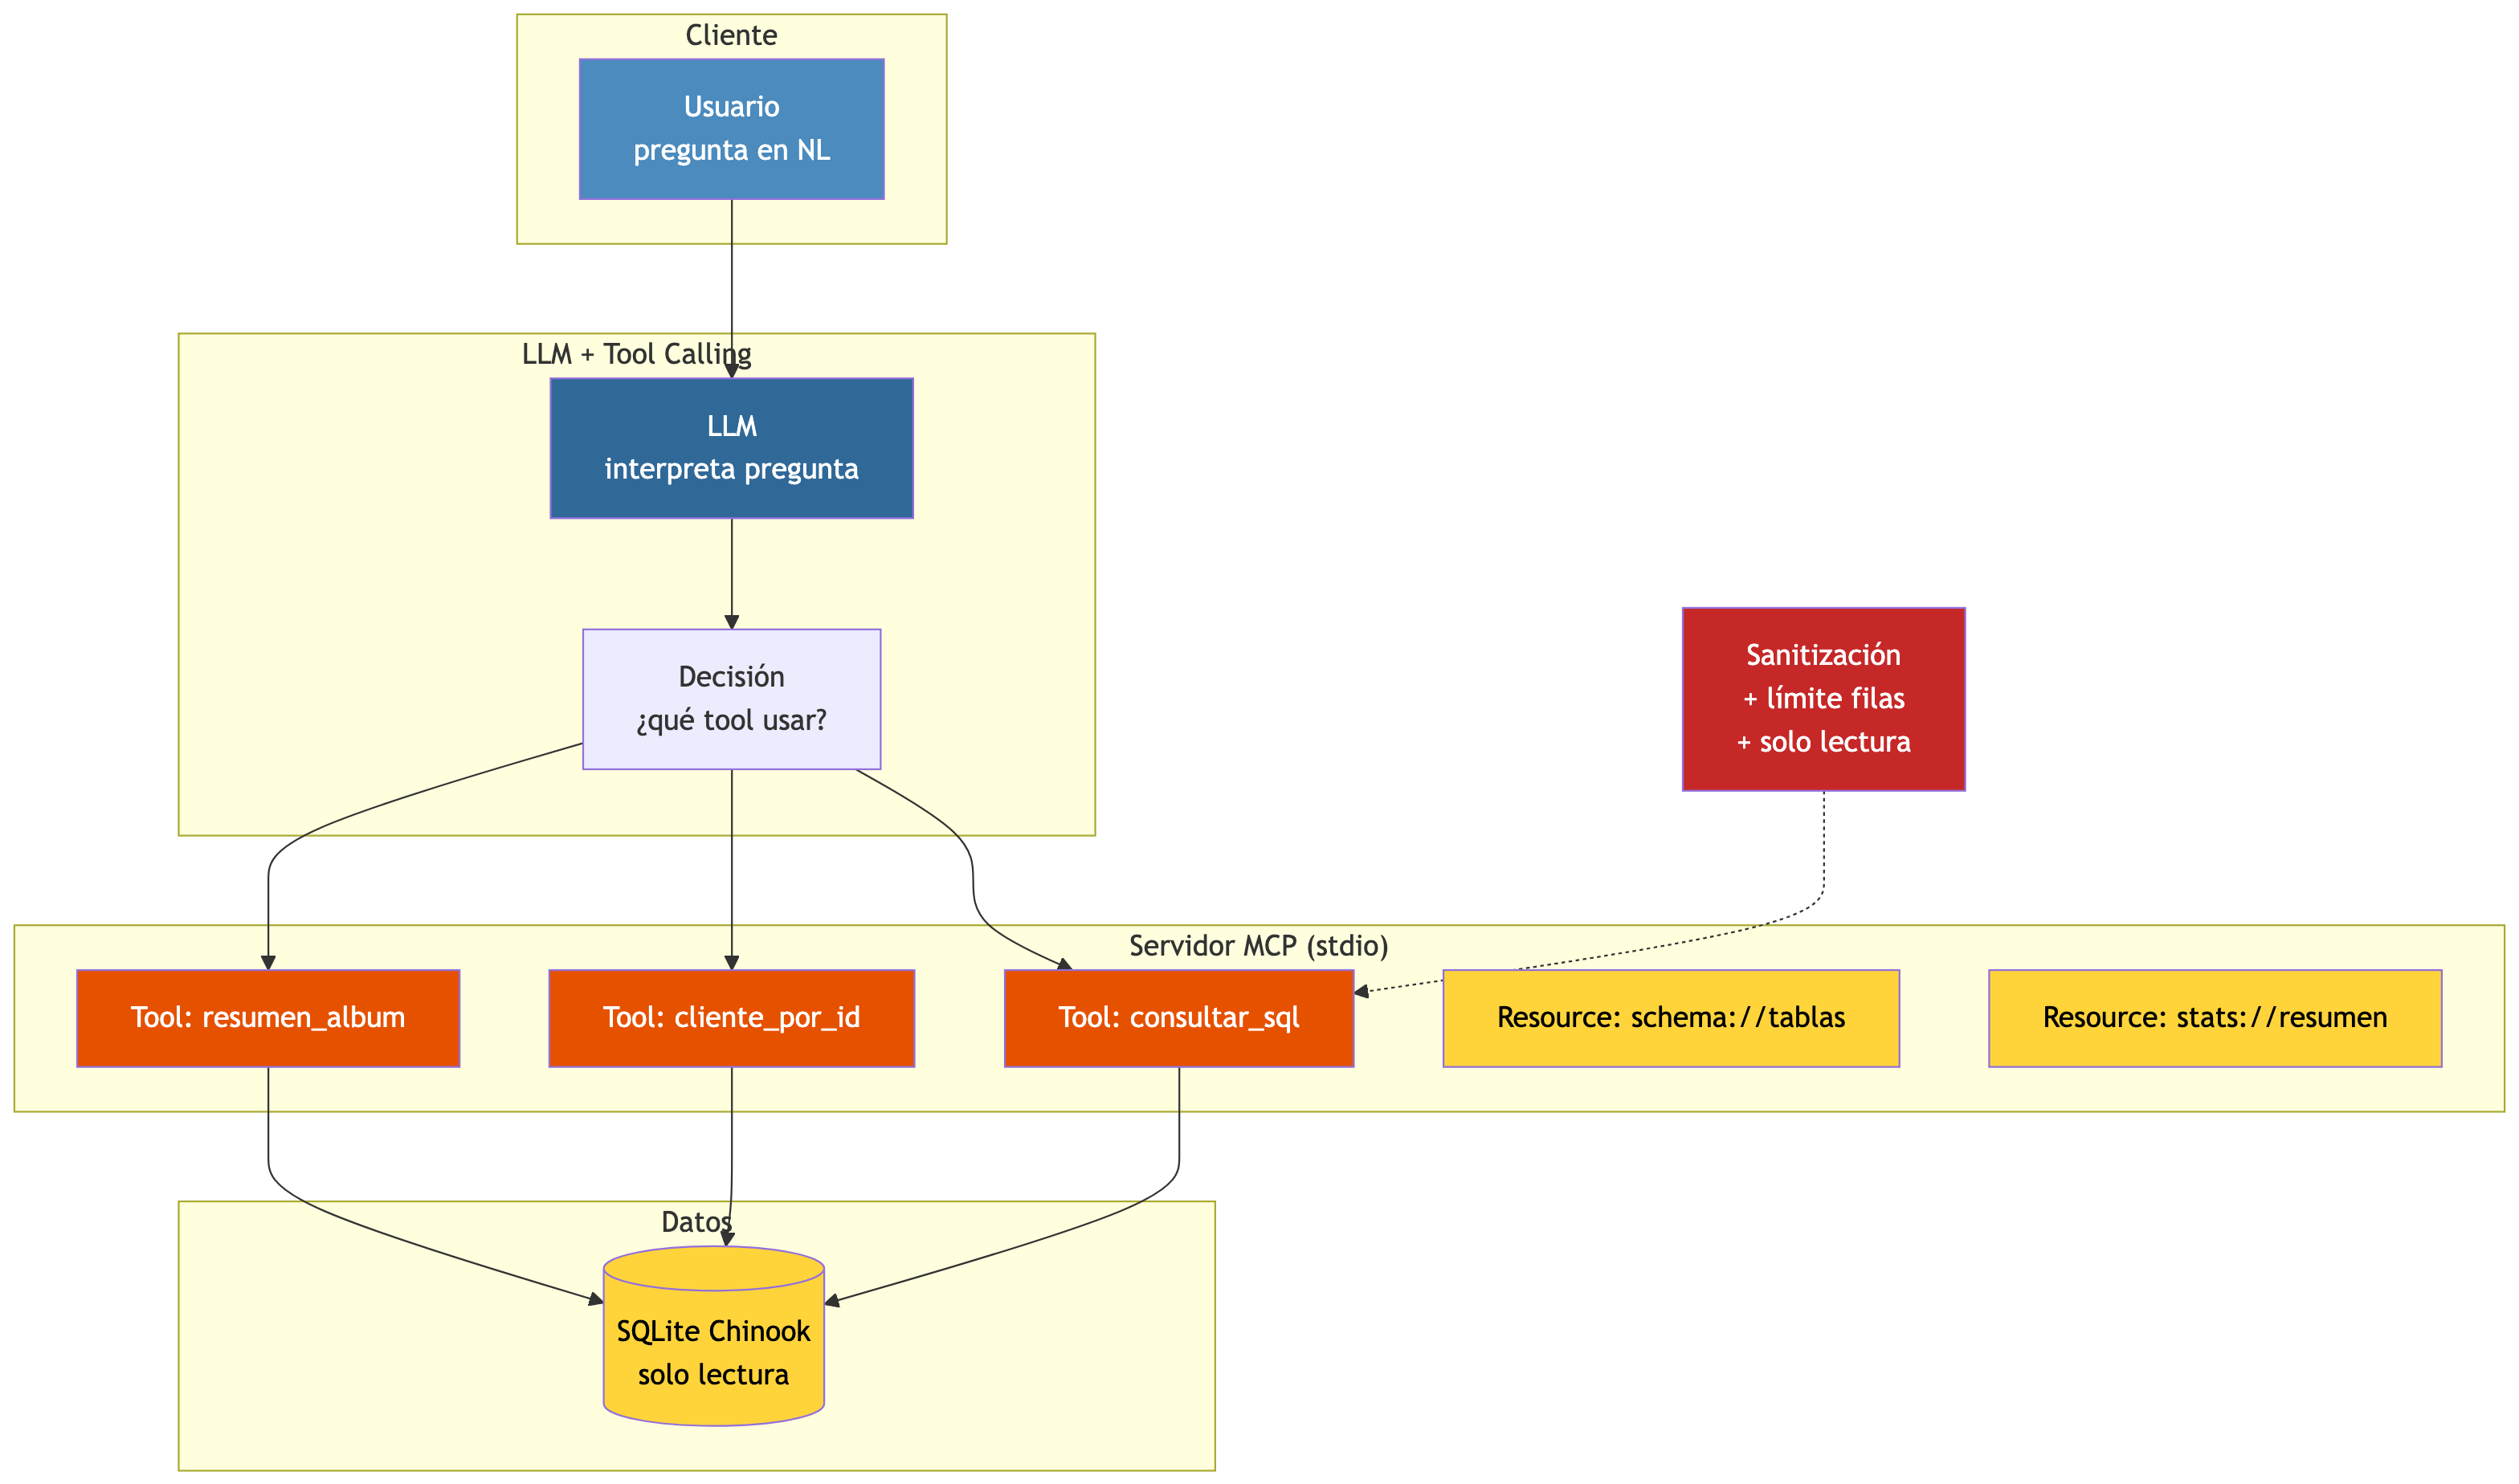
<figcaption>Figure 2</figcaption>
</figure>

------------------------------------------------------------------------

# Ejercicios

> **Para afianzar lo aprendido**
>
> Estos ejercicios no se entregan, pero te preparan para el HPD 4
> evaluable y el proyecto integrador.
>
> ------------------------------------------------------------------------
>
> **A1 — Añade una tool clientes_por_pais**
>
> Crea `@mcp.tool() clientes_por_pais(pais: str)` que devuelva la lista
> de clientes de un país con formato:
> `nombre | ciudad | nº de facturas`. No incluyas email ni teléfono. Si
> el país no existe, devuelve un mensaje indicando que no hay clientes y
> sugiriendo consultar los países disponibles.
>
> > **Note**
> >
> > **Objetivo:** entender que añadir tools especializadas reduce la
> > carga del LLM (no necesita escribir SQL para consultas simples) y
> > que una tool puede decidir qué columnas exponer.
>
> ------------------------------------------------------------------------
>
> **A2 — Añade un resource facturacion://por-anio**
>
> Crea `@mcp.resource("facturacion://por-anio")` que devuelva la
> facturación total y el número de facturas por año.
>
> > **Note**
> >
> > **Objetivo:** distinguir tools (acciones que consultan con
> > parámetros) de resources (datos de solo lectura sin parámetros).
>
> ------------------------------------------------------------------------
>
> **A3 — Modifica el system prompt del cliente**
>
> Cambia el mensaje `system` de `preguntar_al_llm()` para que el
> asistente: - Se niegue a ejecutar queries que contengan nombres de
> tablas no listados en el schema - Exija que toda query incluya al
> menos una condición WHERE - Responda en formato bullet points en lugar
> de texto libre
>
> Prueba con 3 preguntas y compara el comportamiento con el prompt
> original.
>
> > **Note**
> >
> > **Objetivo:** comprobar que el system prompt es tu primera línea de
> > defensa.
>
> ------------------------------------------------------------------------
>
> ### Para seguir explorando (opcional)
>
> **E1 — Añade una tool de auditoría**
>
> Crea `@mcp.tool() auditoria()` que lea de una tabla
> `auditoria(id, timestamp, query, resultado, bloqueado)` que se rellena
> automáticamente desde `consultar_sql`. Cada vez que alguien ejecuta
> una consulta, se registra el timestamp, la query, el resultado
> (truncado a 200 caracteres) y si fue bloqueada por sanitización.
>
> **E2 — Implementa rate limiting**
>
> Modifica `consultar_sql` para que solo permita 10 consultas por
> minuto. Si se supera el límite, devuelve
> `"Límite de consultas alcanzado. Espera X segundos."`
>
> **E3 — Servidor MCP real con stdio**
>
> Investiga cómo lanzar el servidor MCP como script independiente
> (`python servidor_mcp.py`) y conectarte desde un cliente usando
> `fastmcp.Client`. El código base está en
> [02d-mcp.qmd](02d-mcp.qmd#sec-servidor-mcp-script). Adapta tu servidor
> a ese formato y pruébalo con Ollama local.
>
> **E4 — Conecta MCP a tu agente de HPD 2**
>
> Sustituye una de las tools de LangChain de tu agente del HPD 2 por una
> tool que invoque tu servidor MCP. El agente no debería notar la
> diferencia — esa es la magia de MCP.

------------------------------------------------------------------------

> **Entregable**
>
> - Servidor MCP funcional con al menos 3 tools y 2 resources
> - Log de las 5 preguntas de prueba con sus respuestas
> - Checklist de seguridad completado
> - Tabla de evaluación completada
>
> ## Criterios de evaluación
>
> - Servidor MCP operativo con herramientas funcionales
> - Cliente LLM capaz de seleccionar la tool correcta para cada pregunta
> - Sanitización SQL implementada y probada
> - Análisis de riesgos con mitigaciones concretas

# References